# Modelo de árbol de decisión

## Librerias y Configuración

In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("../data/df_final.csv")

numeric_features = [
    "age",
    "baseline_bmi",
    "baseline_charlson_comorbidity_index",
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "n_meds",
    "n_high_risk_meds",
    "serum_creatinine_mg_dl",
    "hemoglobin_g_dl",
    "spo2_percent",
    "respiratory_rate_bpm",
    "heart_rate_bpm",
    "systolic_bp_mmhg",
    "white_blood_cell_count",
    "blood_glucose_mg_dl"
]

categoric_features = [
    "discharge_disposition",
    "disease_category",
    "disease_severity",
    "department",
    "admission_urgency",
    "encounter_type",
    "primary_insurance_provider",
    "socioeconomic_tier",
    "residential_zone",
    "smoker_status",
    "gender",
    "procedure_complexity",
    "hospital_acquired_infection"   
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)



X shape: (13214, 30)
y shape: (13214,)


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
    
cv_results = cross_validate(
    gb_model,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)



RESULTADOS CROSS-VALIDATION 5 FOLDS
accuracy     - Media: 0.7439
precision    - Media: 0.6602
recall       - Media: 0.4629
f1           - Media: 0.5441
roc_auc      - Media: 0.7938
PREDICCIONES
              precision    recall  f1-score   support

No reingreso       0.77      0.88      0.82      1770
   Reingreso       0.66      0.47      0.55       873

    accuracy                           0.75      2643
   macro avg       0.72      0.68      0.69      2643
weighted avg       0.73      0.75      0.73      2643

AUC-ROC Test: 0.7937


In [ ]:
print("RESULTADOS CROSS-VALIDATION 5 FOLDS")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric:12} - Media: {scores.mean():.4f}")


gb_model.fit(X_train, y_train)

y_pred = gb_model.predict(X_test)
y_proba = gb_model.predict_proba(X_test)[:, 1]

print("PREDICCIONES")
print(classification_report(y_test, y_pred, target_names=["No reingreso", "Reingreso"]))
print(f"AUC-ROC Test: {roc_auc_score(y_test, y_proba):.4f}")

RESULTADOS CROSS-VALIDATION 5 FOLDS
accuracy     - Media: 0.7439
precision    - Media: 0.6602
recall       - Media: 0.4629
f1           - Media: 0.5441
roc_auc      - Media: 0.7938
PREDICCIONES
              precision    recall  f1-score   support

No reingreso       0.77      0.88      0.82      1770
   Reingreso       0.66      0.47      0.55       873

    accuracy                           0.75      2643
   macro avg       0.72      0.68      0.69      2643
weighted avg       0.73      0.75      0.73      2643

AUC-ROC Test: 0.7937


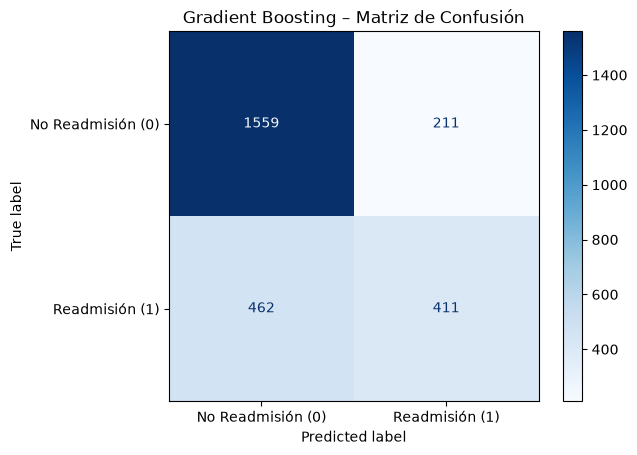

In [32]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=["No Readmisión (0)", "Readmisión (1)"])
disp.plot(cmap="Blues")
plt.title("Gradient Boosting – Matriz de Confusión")
plt.show()